<a href="https://colab.research.google.com/github/menesesblessiebern-hub/Laboratory_exam/blob/main/Meneses_laboratory_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


In [28]:
df = pd.read_csv('telecom_churn.csv')
print("Dataset shape:", df.shape)

Dataset shape: (3333, 21)


In [29]:
if 'phone number' in df.columns:
    df = df.drop(columns=['phone number'])

In [30]:
X = df.drop(columns=['churn'])
y = df['churn'].astype(int)

In [31]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

In [32]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [33]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2666, 19)
Testing set shape: (667, 19)


Text(0.5, 1.0, 'Churn by Customer Service Calls')

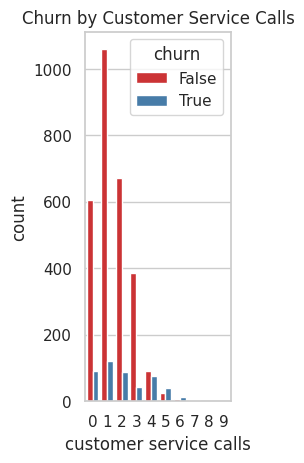

In [36]:
plt.subplot(1, 3, 2)
sns.countplot(x='customer service calls', hue='churn', data=df, palette='Set1')
plt.title('Churn by Customer Service Calls')

/tmp/ipykernel_705/2829126650.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='churn', y='total day minutes', data=df, palette='Set3')


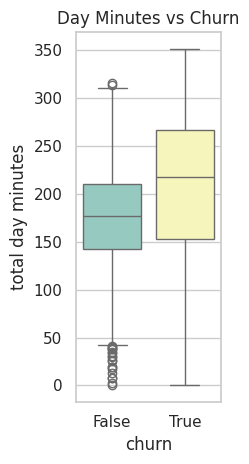

In [13]:
plt.subplot(1, 3, 3)
sns.boxplot(x='churn', y='total day minutes', data=df, palette='Set3')
plt.title('Day Minutes vs Churn')

plt.tight_layout()
plt.show()

In [14]:
df_ml = df.copy()

In [15]:
if 'phone number' in df_ml.columns:
    df_ml = df_ml.drop(columns=['phone number'])

In [16]:
df_ml['international plan'] = df_ml['international plan'].map({'yes': 1, 'no': 0})
df_ml['voice mail plan'] = df_ml['voice mail plan'].map({'yes': 1, 'no': 0})

In [17]:
df_ml = pd.get_dummies(df_ml, columns=['state'], drop_first=True)

In [18]:
X = df_ml.drop(columns=['churn'])
y = df_ml['churn'].astype(int)

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2666, 68)
Testing set shape: (667, 68)


In [22]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [23]:
y_pred = rf_model.predict(X_test)

In [24]:
print("--- Model Evaluation ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

--- Model Evaluation ---
Accuracy Score: 93.25%

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       570
           1       0.91      0.60      0.72        97

    accuracy                           0.93       667
   macro avg       0.92      0.79      0.84       667
weighted avg       0.93      0.93      0.93       667



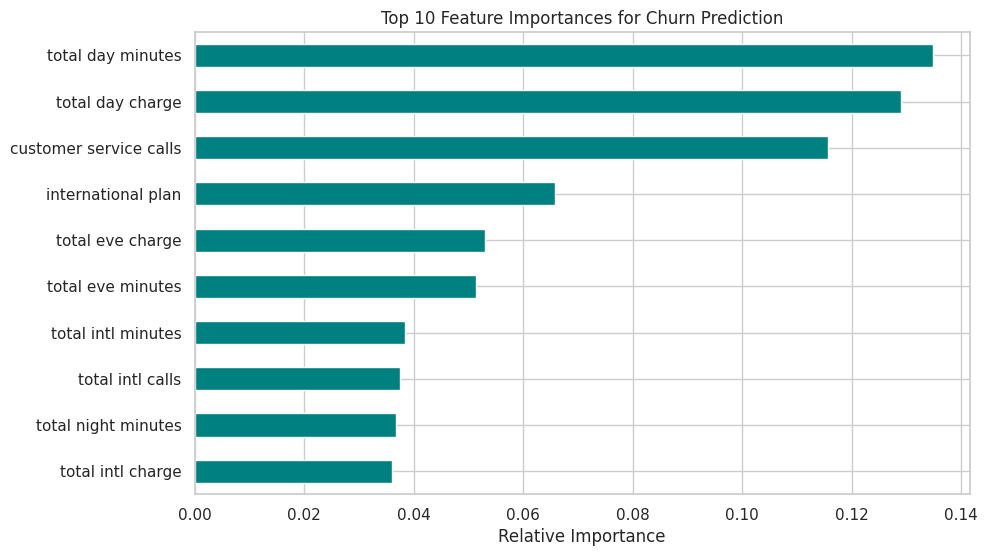

In [25]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances for Churn Prediction')
plt.xlabel('Relative Importance')
plt.gca().invert_yaxis()
plt.show()

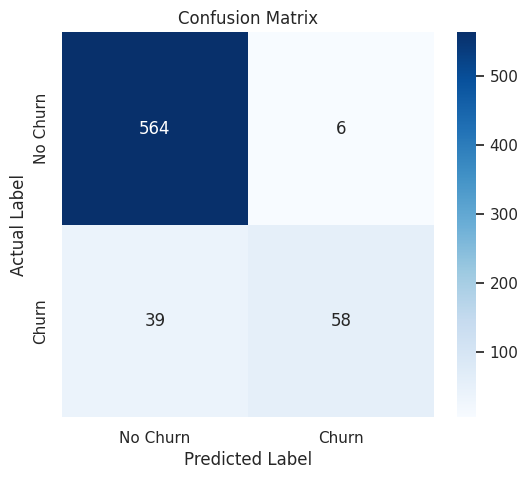

In [26]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

### Missing Value Analysis
Based on our data check (`df.isnull().sum()`), this dataset has **0 missing values** across all columns.

This means that:
- There are no gaps or blank entries that require imputation (such as filling with the mean, median, or mode).
- We did not need to drop any rows or columns due to missing data.
- The data is fully complete and ready for modeling directly after categorical encoding.